In [1]:
import matplotlib, numpy, math, random
import numpy as np
import matplotlib.pyplot as p

eNa = 115
gNa = 120
eK = -12
gK = 36
eL = 10.6
gL = 0.3

alNVal = []
alMVal = []
alHVal = []
beNVal = []
beMVal = []
beHVal = []

nVal = []
mVal = []
hVal = []

naCurVal = []
kCurVal = []
lCurVal = []

volt = [0.0]
current = []
baseCurrent = 0.0
curIn = 0
curRandRange = 0

time = [0.0]
timeStep = 0.01
duration = 0

startTime = 0
endTime = 0

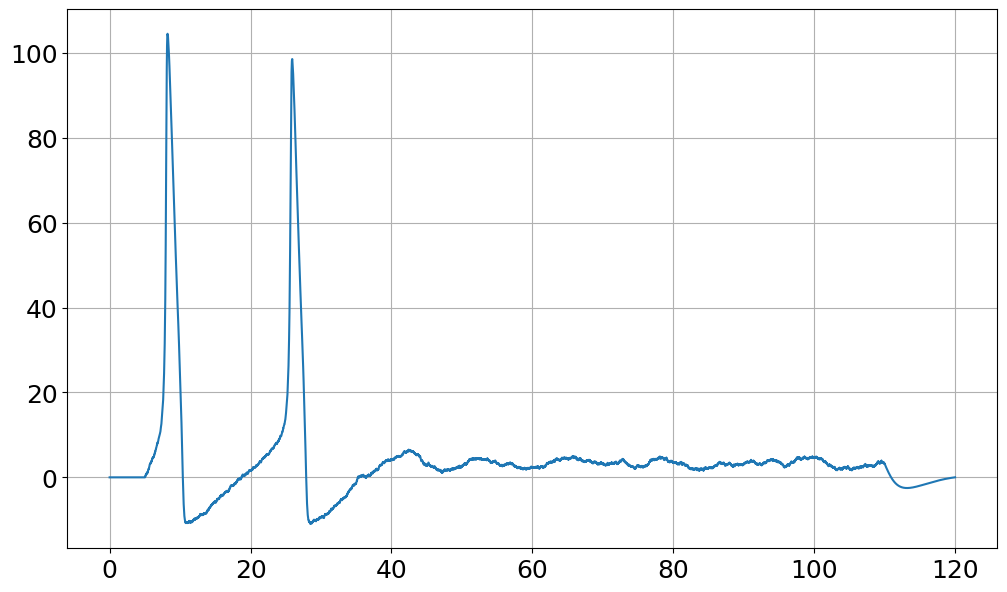

In [2]:
def alphN (v):
    newAlN = (0.01 * (10 - v)) / (np.exp((10 - v) / 10) - 1)
    alNVal.append(newAlN)
    return(newAlN)

def alphM (v):
    newAlM = (0.1 * (25 - v)) / (np.exp((25 - v) / 10) - 1)
    alMVal.append(newAlM)
    return(newAlM)

def alphH (v):
    newAlH = 0.07 * (np.exp(-v / 20))
    alHVal.append(newAlH)
    return(newAlH)

def betaN (v):
    newBeN = 0.125 * (np.exp(-v / 80))
    beNVal.append(newBeN)
    return(newBeN)

def betaM (v):
    newBeM = 4 * (np.exp( -v / 18))
    beMVal.append(newBeM)
    return(newBeM)

def betaH (v):
    newBeH = 1 / (np.exp((30 - v) / 10) + 1)
    beHVal.append(newBeH)
    return(newBeH)

def update (old, deriv):
    return(old+deriv*timeStep)

def dNMH (v,nmh):
    if nmh == nVal[-1]:
        return(alphN(v)*(1-nmh)-betaN(v)*nmh)
    elif nmh == mVal[-1]:
        return(alphM(v)*(1-nmh)-betaM(v)*nmh)
    elif nmh == hVal[-1]:
        return(alphH(v)*(1-nmh)-betaH(v)*nmh)
  
def makeNMH (v):
    if v == 0:
        nVal.append(alphN(v)/(alphN(v)+betaN(v))), alNVal.pop(0)
        mVal.append(alphM(v)/(alphM(v)+betaM(v))), alMVal.pop(0)
        hVal.append(alphH(v)/(alphH(v)+betaH(v))), alHVal.pop(0)
    else:
        nVal.append(update(nVal[-1], dNMH(v,nVal[-1])))
        mVal.append(update(mVal[-1], dNMH(v,mVal[-1])))
        hVal.append(update(hVal[-1], dNMH(v,hVal[-1])))

def naCur (v,m,h):
    newNaCur = gNa * (m ** 3) * h * (v - eNa) 
    naCurVal.append(newNaCur)
    return(newNaCur)

def kCur (v,n):
    newKCur = gK*(n**4)*(v-eK)
    kCurVal.append(newKCur)
    return(newKCur)

def lCur (v):
    newLCur = gL*(v-eL)
    lCurVal.append(newLCur)
    return(newLCur)

def naKLBuild(v,n,m,h):
    return(naCur(v,m,h) + kCur(v,n) + lCur(v))

def dVolt (InCur,v,n,m,h):
    return(InCur - (naKLBuild(v,n,m,h)))

def currentBuild (bC, cIn, cRand, sT, eT):
    if time[-1] < sT or time[-1] > eT:
        current.append(bC)
    else:
        current.append(cIn+(random.uniform(-cRand,cRand)))

def hHmodel (duration, baseCurrent, curIn, curRandRange, startTime, endTime):
    currentBuild(baseCurrent, curIn, curRandRange, startTime, endTime)
    makeNMH(time[-1])
    naKLBuild(0.0, nVal[-1], mVal[-1], hVal[-1])
    while time[-1] < duration:
        currentBuild(baseCurrent, curIn, curRandRange, startTime, endTime)
        makeNMH(volt[-1])
        volt.append(volt[-1]+((dVolt(current[-1], volt[-1], nVal[-1], mVal[-1], hVal[-1]))*timeStep))
        time.append(time[-1]+timeStep)


c = hHmodel(120, 0, 5, 10, 5, 110)


matplotlib.rcParams.update({'font.size': 18})
p.rcParams['figure.figsize'] = [12, 7]
p.grid(True)
p.plot(time, volt)